# TerminalBench 2.1: understandable task selection

This notebook selects a software task that is easy to understand and suitable for later trajectory analysis across the four model × harness combinations. Only resolved TerminalBench 2.1 runs are used.

## Selection criteria

A task is eligible when it:

1. belongs to TerminalBench 2.1;
2. is categorized as software engineering;
3. has resolved runs in all four model × harness quadrants; and
4. can be explained without specialized domain knowledge.

The project convention is retained: unrecognized model names are grouped with open-source models.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "curated" / "terminal_bench_2_1" / "trajectories.jsonl"
assert DATA_PATH.exists(), f"Dataset not found: {DATA_PATH}"

OPEN_SOURCE_MODEL_KEYWORDS = (
    "minimax", "glm", "llama", "mistral", "qwen",
    "deepseek", "gpt-oss",
)
COMMERCIAL_MODEL_KEYWORDS = (
    "claude", "gpt", "gemini", "grok", "o1", "o3", "o4",
)
COMMERCIAL_HARNESSES = {"cursor-cli", "claude-code", "codex", "gemini-cli"}

def model_licence(model):
    name = (model or "").lower()
    if any(key in name for key in OPEN_SOURCE_MODEL_KEYWORDS):
        return "open-source model"
    if any(key in name for key in COMMERCIAL_MODEL_KEYWORDS):
        return "commercial model"
    return "open-source model"

def harness_licence(agent):
    return "commercial harness" if agent in COMMERCIAL_HARNESSES else "open-source harness"

records = []
task_prompts = {}
with DATA_PATH.open(encoding="utf-8") as handle:
    for line in handle:
        row = json.loads(line)
        metadata = row.get("meta", {}).get("downloaded_metadata") or {}
        task_id = row.get("task_id")
        prompt = row.get("meta", {}).get("task_prompt")
        if prompt and task_id not in task_prompts:
            task_prompts[task_id] = prompt
        model_group = model_licence(row.get("model"))
        harness_group = harness_licence(row.get("agent"))
        records.append({
            "task_id": task_id,
            "trial_id": row.get("trial_id"),
            "resolved": row.get("resolved"),
            "agent": row.get("agent"),
            "model": row.get("model"),
            "model_group": model_group,
            "harness_group": harness_group,
            "quadrant": f"{model_group} × {harness_group}",
            "difficulty": metadata.get("difficulty"),
            "category": metadata.get("category"),
            "tags": metadata.get("tags"),
            "step_count": metadata.get("step_count"),
            "tool_call_count": metadata.get("tool_call_count"),
            "command_count": metadata.get("command_count"),
            "duration_seconds": metadata.get("duration_seconds"),
            "prompt_tokens": metadata.get("prompt_tokens"),
            "completion_tokens": metadata.get("completion_tokens"),
            "total_tokens": metadata.get("total_tokens"),
            "trajectory_file": metadata.get("rel_path"),
        })

df = pd.DataFrame(records)
print(f"Loaded {len(df):,} TerminalBench 2.1 trajectories")

Loaded 8,640 TerminalBench 2.1 trajectories


## Eligible tasks

The table below compares software-engineering tasks with resolved coverage in all four quadrants. `minimum_quadrant_runs` is the size of the smallest quadrant for that task.

In [2]:
QUADRANT_ORDER = [
    "commercial model × commercial harness",
    "commercial model × open-source harness",
    "open-source model × commercial harness",
    "open-source model × open-source harness",
]

software_resolved = df[
    df["resolved"].eq(True) & df["category"].eq("software-engineering")
].copy()

coverage = pd.crosstab(software_resolved["task_id"], software_resolved["quadrant"])
coverage = coverage.reindex(columns=QUADRANT_ORDER, fill_value=0)

task_summary = (
    software_resolved.groupby("task_id")
    .agg(
        difficulty=("difficulty", "first"),
        resolved_runs=("trial_id", "size"),
        median_steps=("step_count", "median"),
        median_total_tokens=("total_tokens", "median"),
    )
    .join(coverage)
)
task_summary["minimum_quadrant_runs"] = task_summary[QUADRANT_ORDER].min(axis=1)
eligible = task_summary[task_summary["minimum_quadrant_runs"] > 0].copy()
eligible["difficulty_order"] = eligible["difficulty"].map({"easy": 0, "medium": 1, "hard": 2}).fillna(3)
eligible = eligible.sort_values(["difficulty_order", "median_steps", "task_id"])
eligible_display = eligible.drop(columns="difficulty_order").copy()
eligible_display["median_steps"] = eligible_display["median_steps"].round(1)
eligible_display["median_total_tokens"] = eligible_display["median_total_tokens"].round(0)
eligible_display

,difficulty,resolved_runs,median_steps,median_total_tokens,commercial model × commercial harness,commercial model × open-source harness,open-source model × commercial harness,open-source model × open-source harness,minimum_quadrant_runs
task_id,,,,,,,,,
terminal-bench/prove-plus-comm,easy,84,6.5,20392.0,49,25,5,5,5
terminal-bench/fix-git,easy,85,10.0,99818.0,50,25,5,5,5
terminal-bench/cobol-modernization,easy,81,27.0,606481.0,46,25,5,5,5
terminal-bench/code-from-image,medium,79,8.0,65648.0,47,24,3,5,3
terminal-bench/git-leak-recovery,medium,84,10.0,84778.0,50,24,5,5,5
terminal-bench/kv-store-grpc,medium,60,10.0,37820.0,28,24,4,4,4
terminal-bench/polyglot-c-py,medium,84,10.0,156286.0,50,24,5,5,5
terminal-bench/headless-terminal,medium,77,12.0,127992.0,45,22,5,5,5
terminal-bench/pypi-server,medium,62,12.5,53701.0,27,25,5,5,5


## Selected task: `terminal-bench/fix-git`

This is the clearest choice for the next qualitative analysis. It is rated **easy**, uses familiar version-control concepts, and has strong resolved coverage in every quadrant. Unlike the other easy options, it does not require Coq theorem proving or COBOL knowledge.

The task is also useful for the thesis because agents can make visibly different decisions: search the reflog immediately or investigate other locations first; inspect the lost commit briefly or deeply; merge or cherry-pick; and resolve the merge conflict manually or with Git's `theirs` version.

In [3]:
SELECTED_TASK = "terminal-bench/fix-git"
selected_task_runs = software_resolved[software_resolved["task_id"].eq(SELECTED_TASK)].copy()

display(Markdown("### Original task prompt"))
display(Markdown(f"> {task_prompts[SELECTED_TASK]}"))

display(Markdown("### Resolved coverage"))
coverage_table = (
    selected_task_runs.groupby("quadrant")
    .agg(
        resolved_runs=("trial_id", "size"),
        median_steps=("step_count", "median"),
        median_time_seconds=("duration_seconds", "median"),
        median_total_tokens=("total_tokens", "median"),
    )
    .reindex(QUADRANT_ORDER)
)
coverage_table = coverage_table.round({
    "median_steps": 1,
    "median_time_seconds": 1,
    "median_total_tokens": 0,
})
coverage_table

### Original task prompt

> I just made some changes to my personal site and checked out master, but now I can't find those changes. Please help me find them and merge them into master.


### Resolved coverage

,resolved_runs,median_steps,median_time_seconds,median_total_tokens
quadrant,,,,
commercial model × commercial harness,50,11.0,89.8,123762.0
commercial model × open-source harness,25,7.0,117.2,21960.0
open-source model × commercial harness,5,19.0,67.1,148840.0
open-source model × open-source harness,5,22.0,128.8,403460.0


## What is happening in this task?

The user created a commit while Git was in **detached HEAD** mode. After checking out `master`, the commit was no longer shown in the normal branch history, but Git still retained it.

A direct solution is:

1. inspect the repository state;
2. use `git reflog` to find the lost commit (`c499730`, "Move to Stanford");
3. inspect that commit;
4. merge it into `master`;
5. resolve the conflict in `_includes/about.md`; and
6. commit and verify that the working tree is clean.

This makes the trajectory easy to decode: every command corresponds to either **search**, **verification**, **integration**, **conflict resolution**, or **final validation**.

## Four representative resolved runs

These four runs use the same model–harness pair types as the earlier analysis. They are examples for qualitative comparison, not estimates of an entire quadrant.

In [4]:
REPRESENTATIVE_TRIALS = {
    "commercial model × commercial harness": "3b990346-d3dc-57bc-a47d-5e214ee059dc",
    "commercial model × open-source harness": "3f5cab68-6bd9-5dbd-a7fb-7cbaafce335d",
    "open-source model × commercial harness": "7997d04c-7612-5bd6-8128-f1771f0fdf19",
    "open-source model × open-source harness": "7ac8c270-90ef-54ea-9319-f26786f2ae53",
}

representative_runs = (
    selected_task_runs[selected_task_runs["trial_id"].isin(REPRESENTATIVE_TRIALS.values())]
    .set_index("quadrant")
    .reindex(QUADRANT_ORDER)
    .reset_index()
)
representative_display = representative_runs[[
    "quadrant", "agent", "model", "step_count", "tool_call_count",
    "duration_seconds", "prompt_tokens", "completion_tokens",
    "total_tokens", "trial_id",
]].copy()
representative_display["duration_seconds"] = representative_display["duration_seconds"].round(1)
representative_display

,quadrant,agent,model,step_count,tool_call_count,duration_seconds,prompt_tokens,completion_tokens,total_tokens,trial_id
0,commercial model × commercial harness,claude-code,claude-opus-4-8,9.0,7.0,68.0,29032.0,3066.0,32098.0,3b990346-d3dc-57bc-a47d-5e214ee059dc
1,commercial model × open-source harness,terminus-2,gemini/gemini-3.1-pro-preview,7.0,12.0,78.8,12319.0,4222.0,16541.0,3f5cab68-6bd9-5dbd-a7fb-7cbaafce335d
2,open-source model × commercial harness,claude-code,glm-5.1,19.0,9.0,58.7,147583.0,789.0,148372.0,7997d04c-7612-5bd6-8128-f1771f0fdf19
3,open-source model × open-source harness,mini-swe-agent,openai/muse-spark-1.1,22.0,20.0,128.8,395932.0,7528.0,403460.0,7ac8c270-90ef-54ea-9319-f26786f2ae53


## Simple trajectory viewer

Run the next two cells, then change `RUN_TO_VIEW` to any quadrant name from `QUADRANT_ORDER`. Observations are shortened only for display; the underlying trajectory is unchanged.

In [5]:
representative_rows = {}
wanted_trials = set(REPRESENTATIVE_TRIALS.values())
with DATA_PATH.open(encoding="utf-8") as handle:
    for line in handle:
        row = json.loads(line)
        if row.get("trial_id") in wanted_trials:
            representative_rows[row["trial_id"]] = row

assert representative_rows.keys() == wanted_trials

def shorten(value, limit=700):
    text = " ".join((value or "").split())
    return text if len(text) <= limit else text[:limit] + " …"

def trajectory_table(quadrant, observation_limit=700):
    trial_id = REPRESENTATIVE_TRIALS[quadrant]
    row = representative_rows[trial_id]
    return pd.DataFrame([
        {
            "step": step.get("index"),
            "thought": shorten(step.get("thought"), 450),
            "action": shorten(step.get("action"), 700),
            "observation": shorten(step.get("observation"), observation_limit),
        }
        for step in row.get("steps", [])
    ])

In [6]:
RUN_TO_VIEW = "commercial model × commercial harness"
trial_id = REPRESENTATIVE_TRIALS[RUN_TO_VIEW]
run = representative_rows[trial_id]
display(Markdown(f"### {RUN_TO_VIEW}  \n`{run['agent']}` + `{run['model']}`"))
display(trajectory_table(RUN_TO_VIEW))

### commercial model × commercial harness  
`claude-code` + `claude-opus-4-8`

,step,thought,action,observation
0,0,"Check git status, branches, stashes, and reflog","Bash git status && echo ""---BRANCHES---"" && gi...","On branch master nothing to commit, working tr..."
1,1,Show details of the orphaned commit,Bash git show --stat c499730,commit c499730ae050deb27e5d22972ea28daf778060f...
2,2,Show what master's latest commit changed,Bash git show --stat d7d3e4b,commit d7d3e4ba9350f634d92d39ace2b471433ee57d5...
3,3,Merge orphaned commit into master,Bash git merge c499730 --no-edit,Exit code 1 Auto-merging _includes/about.md CO...
4,4,View the conflicted file,Bash cat _includes/about.md,<<<<<<< HEAD I am a sixth PhD candidate at the...
5,5,,Edit,The file /app/personal-site/_includes/about.md...
6,6,Commit the merge resolution and verify,Bash git add _includes/about.md && git commit ...,[master c71459e] Merge commit 'c499730' --- c7...
7,7,Done! Your changes are recovered and merged in...,,


## Analysis design

The analysis below holds the harness constant inside each section. Section 1 compares an open-source and a commercial model using the commercial Claude Code harness. Section 2 compares two commercial models using the open-source Terminus-2 harness.

There is no resolved `fix-git` trajectory where a single open-source harness was used with both model licence groups. `mini-swe-agent` only has Muse Spark, while `terminus-2` only has commercial models. Comparing those two runs as though the harness were fixed would confound model and harness effects.

In [7]:
import matplotlib.pyplot as plt

ANALYSIS_TRIALS = {
    "Claude Opus 4.8": "3b990346-d3dc-57bc-a47d-5e214ee059dc",
    "GLM 5.1": "7997d04c-7612-5bd6-8128-f1771f0fdf19",
    "Gemini 3.1 Pro (Gemini CLI)": "3aec13b8-5ea8-5e5e-9658-6821095a026e",
    "Gemini 3.1 Pro": "dd6ed4e0-1076-5299-9fda-7481cff62e68",
    "GPT-5.5": "37c765b2-4df1-5454-bf00-ea0017003c6f",
}

analysis_rows = {}
wanted_trials = set(ANALYSIS_TRIALS.values())
with DATA_PATH.open(encoding="utf-8") as handle:
    for line in handle:
        row = json.loads(line)
        if row.get("trial_id") in wanted_trials:
            analysis_rows[row["trial_id"]] = row
assert analysis_rows.keys() == wanted_trials

def analysis_metrics(model_labels):
    order = [ANALYSIS_TRIALS[label] for label in model_labels]
    table = selected_task_runs[selected_task_runs["trial_id"].isin(order)].copy()
    table["model_example"] = table["trial_id"].map({value: key for key, value in ANALYSIS_TRIALS.items()})
    table["model_example"] = pd.Categorical(table["model_example"], categories=model_labels, ordered=True)
    return table.sort_values("model_example")

def plot_metrics(table, title, colour_by="model_group"):
    labels = table["model_example"].astype(str).tolist()
    commercial_label = "commercial harness" if colour_by == "harness_group" else "commercial model"
    colours = ["#4C78A8" if group == commercial_label else "#59A14F" for group in table[colour_by]]
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    axes[0].bar(labels, table["step_count"], color=colours)
    axes[0].set_title("Reported steps")
    axes[0].set_ylabel("Steps")
    axes[1].bar(labels, table["duration_seconds"], color=colours)
    axes[1].set_title("Completion time")
    axes[1].set_ylabel("Seconds")
    axes[2].bar(labels, table["prompt_tokens"], label="Prompt", color="#76B7B2")
    axes[2].bar(labels, table["completion_tokens"], bottom=table["prompt_tokens"], label="Completion", color="#F28E2B")
    axes[2].set_title("Token usage")
    axes[2].set_ylabel("Tokens")
    axes[2].legend()
    for axis in axes:
        axis.tick_params(axis="x", rotation=15)
        axis.grid(axis="y", alpha=0.2)
    fig.suptitle(title, y=1.03)
    plt.tight_layout()
    plt.show()

def analysis_trajectory(model_label, observation_limit=900):
    trial_id = ANALYSIS_TRIALS[model_label]
    row = analysis_rows[trial_id]
    return pd.DataFrame([
        {
            "step": step.get("index"),
            "thought": shorten(step.get("thought"), 450),
            "action": shorten(step.get("action"), 700),
            "observation": shorten(step.get("observation"), observation_limit),
        }
        for step in row.get("steps", [])
    ])

# Section 1 — Commercial harness: Claude Code

This section holds `claude-code` constant and compares:

- **Claude Opus 4.8:** commercial model
- **GLM 5.1:** open-source model

,model_example,model_group,agent,step_count,tool_call_count,command_count,duration_seconds,prompt_tokens,completion_tokens,total_tokens,trial_id
1414,Claude Opus 4.8,commercial model,claude-code,9.0,7.0,6.0,68.0,29032.0,3066.0,32098.0,3b990346-d3dc-57bc-a47d-5e214ee059dc
645,GLM 5.1,open-source model,claude-code,19.0,9.0,7.0,58.7,147583.0,789.0,148372.0,7997d04c-7612-5bd6-8128-f1771f0fdf19


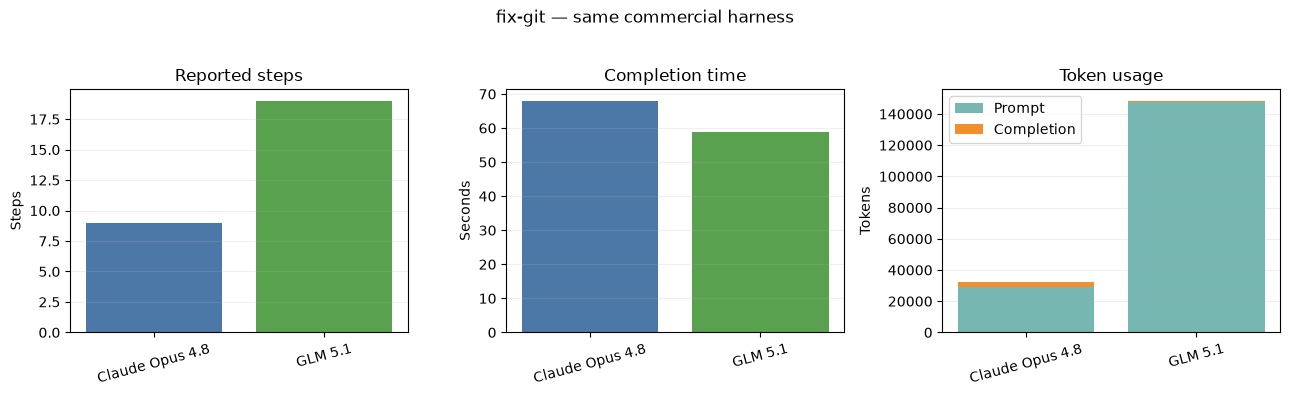

In [8]:
section_1 = analysis_metrics(["Claude Opus 4.8", "GLM 5.1"])
section_1_display = section_1[[
    "model_example", "model_group", "agent", "step_count",
    "tool_call_count", "command_count", "duration_seconds", "prompt_tokens",
    "completion_tokens", "total_tokens", "trial_id",
]].copy()
section_1_display["duration_seconds"] = section_1_display["duration_seconds"].round(1)
display(section_1_display)
plot_metrics(section_1, "fix-git — same commercial harness")

## Interpretation

Both models followed the same main algorithm: inspect Git state, locate `c499730` in the reflog, inspect the commit, merge it, resolve `_includes/about.md`, and commit the result.

| Category | Claude Opus 4.8 | GLM 5.1 |
|---|---|---|
| Discovery | Batched status, branches, stash and reflog in one command | Checked stash, branches and reflog sequentially |
| Evidence | Inspected the lost commit and the latest master commit | Inspected the full diff and lost commit statistics |
| Conflict resolution | Used Claude Code's targeted `Edit` tool | Used `Read` followed by a full-file `Write` |
| Validation | Verified Git history and clean status after committing | The stored trajectory ends after the commit |
| Trade-off | More concise and strongly verified | Faster wall-clock completion, but more sequential and much higher prompt-token use |

Claude Opus used 9 reported steps, 7 tool calls and 32,098 tokens. GLM used 19 reported steps, 9 tool calls and 148,372 tokens. GLM finished about 9 seconds faster, but reported about 4.6 times as many total tokens. Most of that difference is prompt tokens, not generated completion text. Because the harness is fixed, these behavioral differences are more plausibly associated with the model interaction, although two individual trajectories cannot establish a causal model effect.

In [9]:
display(Markdown("### Claude Opus 4.8 trajectory"))
display(analysis_trajectory("Claude Opus 4.8"))
display(Markdown("### GLM 5.1 trajectory"))
display(analysis_trajectory("GLM 5.1"))

### Claude Opus 4.8 trajectory

,step,thought,action,observation
0,0,"Check git status, branches, stashes, and reflog","Bash git status && echo ""---BRANCHES---"" && gi...","On branch master nothing to commit, working tr..."
1,1,Show details of the orphaned commit,Bash git show --stat c499730,commit c499730ae050deb27e5d22972ea28daf778060f...
2,2,Show what master's latest commit changed,Bash git show --stat d7d3e4b,commit d7d3e4ba9350f634d92d39ace2b471433ee57d5...
3,3,Merge orphaned commit into master,Bash git merge c499730 --no-edit,Exit code 1 Auto-merging _includes/about.md CO...
4,4,View the conflicted file,Bash cat _includes/about.md,<<<<<<< HEAD I am a sixth PhD candidate at the...
5,5,,Edit,The file /app/personal-site/_includes/about.md...
6,6,Commit the merge resolution and verify,Bash git add _includes/about.md && git commit ...,[master c71459e] Merge commit 'c499730' --- c7...
7,7,Done! Your changes are recovered and merged in...,,


### GLM 5.1 trajectory

,step,thought,action,observation
0,0,Let me investigate the git state to find your ...,,
1,1,Check for stashed changes,Bash git stash list,"(Bash completed with no output) [metadata] {""n..."
2,2,List all branches,Bash git branch -a,"* master [stdout] * master [metadata] {""noOutp..."
3,3,Check recent git reflog to find where changes ...,Bash git reflog --all -30,d7d3e4b refs/heads/master@{0}: reset: moving t...
4,4,Found it. The reflog shows a commit `c499730` ...,,
5,5,Show diff between master and the lost commit,Bash git diff master c499730,diff --git a/_includes/about.md b/_includes/ab...
6,6,"Show the ""Move to Stanford"" commit details",Bash git log c499730 -1 --stat,commit c499730ae050deb27e5d22972ea28daf778060f...
7,7,"Your changes are in commit `c499730` (""Move to...",,
8,8,"Merge the ""Move to Stanford"" commit into master",Bash git merge c499730,Exit code 1 Auto-merging _includes/about.md CO...
9,9,There's a conflict in `_includes/about.md`. Le...,,


# Section 2 — Open-source harness: Terminus-2

This section holds `terminus-2` constant and compares two available commercial models:

- **Gemini 3.1 Pro Preview**
- **GPT-5.5**

An open-source-model example is not available for this harness and task.

,model_example,model_group,agent,step_count,tool_call_count,command_count,duration_seconds,prompt_tokens,completion_tokens,total_tokens,trial_id
7733,Gemini 3.1 Pro,commercial model,terminus-2,7.0,14.0,12.0,85.9,14479.0,4485.0,18964.0,dd6ed4e0-1076-5299-9fda-7481cff62e68
7868,GPT-5.5,commercial model,terminus-2,7.0,22.0,20.0,122.3,18542.0,3418.0,21960.0,37c765b2-4df1-5454-bf00-ea0017003c6f


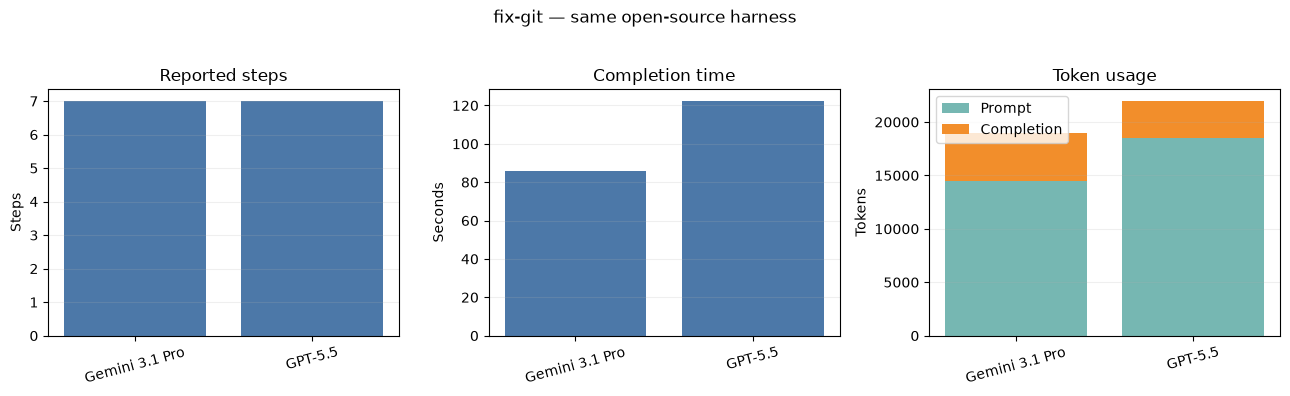

In [10]:
section_2 = analysis_metrics(["Gemini 3.1 Pro", "GPT-5.5"])
section_2_display = section_2[[
    "model_example", "model_group", "agent", "step_count",
    "tool_call_count", "command_count", "duration_seconds", "prompt_tokens",
    "completion_tokens", "total_tokens", "trial_id",
]].copy()
section_2_display["duration_seconds"] = section_2_display["duration_seconds"].round(1)
display(section_2_display)
plot_metrics(section_2, "fix-git — same open-source harness")

## Interpretation

Both models found the detached commit and produced a resolved repository, but they made different safety–efficiency trade-offs.

| Category | Gemini 3.1 Pro | GPT-5.5 |
|---|---|---|
| Discovery | Direct status, branches and reflog inspection | Added stash and graphical history inspection |
| Recovery safety | Merged the detached commit directly | Created a named recovery branch before merging |
| Conflict resolution | Selected the incoming version with `git checkout --theirs` | Inspected diffs and reconstructed the desired file manually |
| Validation | Committed and checked status | Ran `diff --check`, status checks and final graph inspection |
| Trade-off | Direct and efficient | More defensive and auditable, but more expensive |

Both runs report 7 steps, yet Gemini records 14 tool calls and 12 commands while GPT-5.5 records 22 tool calls and 20 commands. This shows that the harness-level step count is too coarse to represent the actual amount of terminal work. Gemini completed in 85.9 seconds with 18,964 tokens; GPT-5.5 took 122.3 seconds and 21,960 tokens.

A second observability issue is visible here: both Terminus-2 trajectories have empty stored thought fields and generic `bash_command` actions. The actual commands must be reconstructed from terminal observations. Therefore, algorithmic claims are less certain than in the Claude Code comparison.

In [11]:
display(Markdown("### Gemini 3.1 Pro trajectory"))
display(analysis_trajectory("Gemini 3.1 Pro"))
display(Markdown("### GPT-5.5 trajectory"))
display(analysis_trajectory("GPT-5.5"))

### Gemini 3.1 Pro trajectory

,step,thought,action,observation
0,0,,bash_command,
1,1,,bash_command,
2,2,,bash_command,Previous response had warnings: WARNINGS: - Ex...
3,3,,bash_command,
4,4,,bash_command,
5,5,,bash_command,New Terminal Output: root@12ebad42-ed7d-4ee6-8...
6,6,,bash_command,New Terminal Output: root@12ebad42-ed7d-4ee6-8...
7,7,,bash_command,
8,8,,bash_command,
9,9,,bash_command,


### GPT-5.5 trajectory

,step,thought,action,observation
0,0,,bash_command,
1,1,,bash_command,
2,2,,bash_command,
3,3,,bash_command,
4,4,,bash_command,New Terminal Output: root@e53e9a26-8bd3-4ac9-b...
5,5,,bash_command,
6,6,,bash_command,
7,7,,bash_command,
8,8,,bash_command,
9,9,,bash_command,New Terminal Output: root@e53e9a26-8bd3-4ac9-b...


# Section 3 — Same model, different harness

This section holds the model constant and compares the same resolved `fix-git` task across two harnesses:

- **Gemini CLI:** commercial harness + `gemini-3.1-pro-preview`
- **Terminus-2:** open-source harness + `gemini/gemini-3.1-pro-preview`

The provider prefix is removed during canonicalization, so both runs use the same Gemini 3.1 Pro Preview model version.

,model_example,model,agent,harness_group,step_count,tool_call_count,command_count,duration_seconds,prompt_tokens,completion_tokens,total_tokens,trial_id
5705,Gemini 3.1 Pro (Gemini CLI),gemini-3.1-pro-preview,gemini-cli,commercial harness,10.0,9.0,6.0,87.9,127314.0,2125.0,129439.0,3aec13b8-5ea8-5e5e-9658-6821095a026e
7733,Gemini 3.1 Pro,gemini/gemini-3.1-pro-preview,terminus-2,open-source harness,7.0,14.0,12.0,85.9,14479.0,4485.0,18964.0,dd6ed4e0-1076-5299-9fda-7481cff62e68


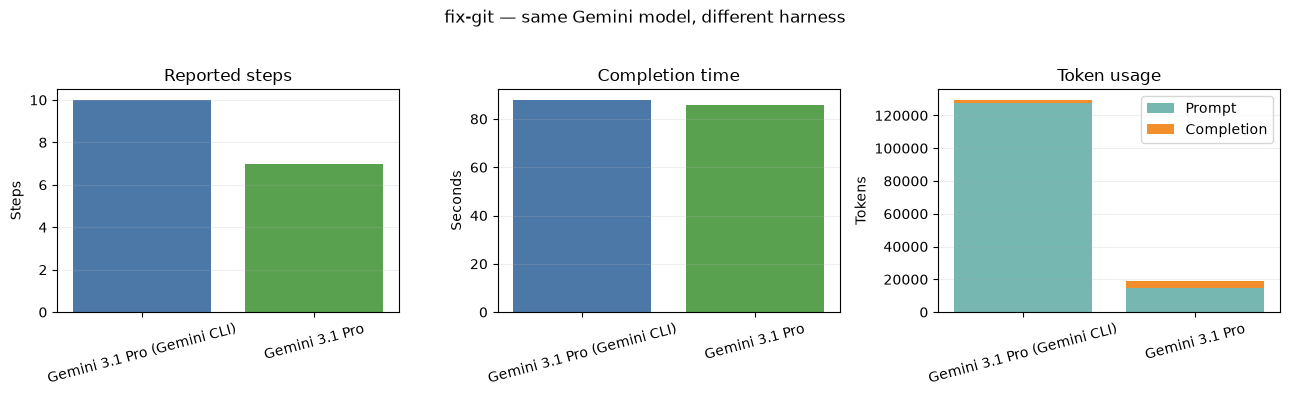

In [12]:
section_3 = analysis_metrics(["Gemini 3.1 Pro (Gemini CLI)", "Gemini 3.1 Pro"])
section_3_display = section_3[[
    "model_example", "model", "agent", "harness_group",
    "step_count", "tool_call_count", "command_count", "duration_seconds",
    "prompt_tokens", "completion_tokens", "total_tokens", "trial_id",
]].copy()
section_3_display["duration_seconds"] = section_3_display["duration_seconds"].round(1)
display(section_3_display)
plot_metrics(section_3, "fix-git — same Gemini model, different harness", colour_by="harness_group")

## Interpretation

Both harnesses led Gemini to the same high-level solution: inspect the repository, locate `c499730` through the reflog, inspect or confirm the commit, merge it, resolve `_includes/about.md`, commit, and verify the repository. The major differences are the interface, conflict-resolution mechanism, trajectory visibility, and reported resource use.

| Category | Gemini CLI | Terminus-2 |
|---|---|---|
| Harness interface | Structured tools: `update_topic`, `run_shell_command`, and `write_file` | Stateful terminal using generic `bash_command` actions |
| Initial investigation | Batched status, branches, log and reflog | Status, branches and reflog through terminal interactions |
| Commit inspection | Displayed the complete lost commit before merging | Followed a more direct terminal path |
| Conflict resolution | Replaced the file through `write_file` | Used Git's `checkout --theirs` and staged the result |
| Finalisation | Produced a user-facing explanation and topic update | Used an explicit two-stage `mark_task_complete` protocol |
| Observability | Thought text and specific tool actions are visible | Thought is empty and actions are generic; commands are embedded in observations |
| Trade-off | More interpretable trajectory, but much higher reported prompt-token use | Less observable, but substantially more token-efficient |

Gemini CLI reports 10 steps, 9 tool calls, 6 commands, 87.9 seconds and 129,439 tokens. Terminus-2 reports 7 steps, 14 tool calls, 12 commands, 85.9 seconds and 18,964 tokens. The completion times are nearly identical, but Gemini CLI reports about 6.8 times as many total tokens. Almost all of the difference comes from prompt tokens: 127,314 versus 14,479.

The step result is especially important: Terminus-2 reports fewer steps while executing more tool calls and commands. This confirms that harness-level `step_count` is not a uniform measure of work. Because token accounting and context construction are also performed by the harness, the token difference should be described as a harness-associated difference in reported usage—not proof that the underlying model reasoned 6.8 times more.

In [13]:
display(Markdown("### Gemini CLI trajectory"))
display(analysis_trajectory("Gemini 3.1 Pro (Gemini CLI)"))
display(Markdown("### Terminus-2 trajectory"))
display(analysis_trajectory("Gemini 3.1 Pro"))

### Gemini CLI trajectory

,step,thought,action,observation
0,0,,update_topic,
1,1,"Checking git status, branches, recent commits,...",run_shell_command git status && git branch -a ...,"Current topic: ""Recovering Lost Git Changes"" T..."
2,2,Review the missing commit's contents before me...,run_shell_command git show c499730,Output: commit c499730ae050deb27e5d22972ea28da...
3,3,Merge the missing changes into master.,run_shell_command git merge c499730,Output: Auto-merging _includes/about.md CONFLI...
4,4,Check the merge conflict in about.md,run_shell_command cat _includes/about.md,Output: <<<<<<< HEAD I am a sixth PhD candidat...
5,5,,write_file,Successfully overwrote file: /app/personal-sit...
6,6,Add the resolved file and finish the merge.,run_shell_command git add _includes/about.md &...,Output: [master e86833c] Merge commit 'c499730...
7,7,Verify merge success and repository state.,run_shell_command git status && git log -n 5 -...,"Output: On branch master nothing to commit, wo..."
8,8,,update_topic,"Current topic: ""Changes Successfully Merged"" T..."
9,9,I found your changes! It looks like you made a...,,


### Terminus-2 trajectory

,step,thought,action,observation
0,0,,bash_command,
1,1,,bash_command,
2,2,,bash_command,Previous response had warnings: WARNINGS: - Ex...
3,3,,bash_command,
4,4,,bash_command,
5,5,,bash_command,New Terminal Output: root@12ebad42-ed7d-4ee6-8...
6,6,,bash_command,New Terminal Output: root@12ebad42-ed7d-4ee6-8...
7,7,,bash_command,
8,8,,bash_command,
9,9,,bash_command,


# Section 4 — Same open-source model, different harness

TerminalBench 2.1 contains no resolved task where the same open-source model appears under two harnesses. This section therefore uses the understandable **TerminalBench 2.0 `pypi-server` task** and keeps MiniMax M2.1 constant:

- **Claude Code:** commercial harness + `MiniMax-M2.1` — 4 resolved runs available
- **Terminus-2:** open-source harness + `openai/minimax-m2.1` — 5 resolved runs available

After removing the provider prefix and normalizing case, both model identifiers refer to MiniMax M2.1. The representative runs are close to the median reported step count within each model–harness pair.

The task is to create the `vectorops` Python package (version 0.1.0), implement a `dotproduct` function, build the package, host it on a local PyPI-compatible server on port 8080, install it through `pip --index-url`, and verify that it works.

,model_example,model,agent,harness_group,step_count,tool_call_count,command_count,duration_seconds,prompt_tokens,completion_tokens,total_tokens,trial_id
1,MiniMax M2.1 (Claude Code),MiniMax-M2.1,claude-code,commercial harness,54,22,14,453.1,900508,3115,903623,c028a683-2879-47c3-87c6-a9a2f7782014
0,MiniMax M2.1 (Terminus-2),openai/minimax-m2.1,terminus-2,open-source harness,9,21,19,100.7,32885,3767,36652,531427a8-3e2d-4b69-a7bc-e9512f2a9a64


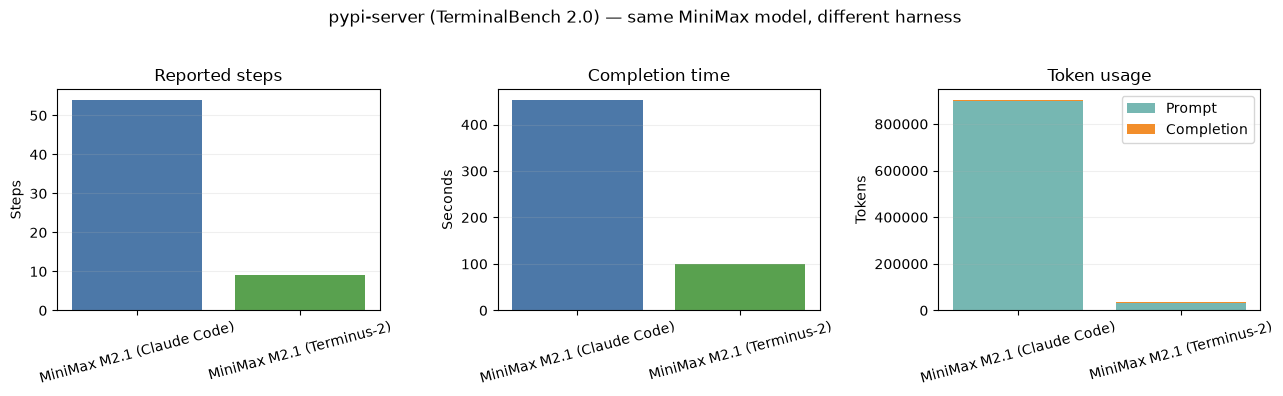

In [14]:
TB20_DATA_PATH = PROJECT_ROOT / "data" / "curated" / "terminal_bench_2_0" / "trajectories.jsonl"
TB20_TASK_ID = "5c5f465d60305289c69aa88e385675925e684eb09c256610e0abca10375efc3876"
TB20_ANALYSIS_TRIALS = {
    "MiniMax M2.1 (Claude Code)": "c028a683-2879-47c3-87c6-a9a2f7782014",
    "MiniMax M2.1 (Terminus-2)": "531427a8-3e2d-4b69-a7bc-e9512f2a9a64",
}

tb20_analysis_rows = {}
tb20_wanted_trials = set(TB20_ANALYSIS_TRIALS.values())
with TB20_DATA_PATH.open(encoding="utf-8") as handle:
    for line in handle:
        row = json.loads(line)
        if row.get("trial_id") in tb20_wanted_trials:
            tb20_analysis_rows[row["trial_id"]] = row
assert tb20_analysis_rows.keys() == tb20_wanted_trials

tb20_records = []
trial_to_label = {value: key for key, value in TB20_ANALYSIS_TRIALS.items()}
for trial_id, row in tb20_analysis_rows.items():
    metadata = row.get("meta", {}).get("downloaded_metadata") or {}
    tb20_records.append({
        "model_example": trial_to_label[trial_id],
        "model": row.get("model"),
        "model_group": "open-source model",
        "agent": row.get("agent"),
        "harness_group": harness_licence(row.get("agent")),
        "step_count": metadata.get("step_count"),
        "tool_call_count": metadata.get("tool_call_count"),
        "command_count": metadata.get("command_count"),
        "duration_seconds": metadata.get("duration_seconds"),
        "prompt_tokens": metadata.get("prompt_tokens"),
        "completion_tokens": metadata.get("completion_tokens"),
        "total_tokens": metadata.get("total_tokens"),
        "trial_id": trial_id,
    })

section_4 = pd.DataFrame(tb20_records)
section_4["model_example"] = pd.Categorical(
    section_4["model_example"], categories=list(TB20_ANALYSIS_TRIALS), ordered=True
)
section_4 = section_4.sort_values("model_example")
section_4_display = section_4[[
    "model_example", "model", "agent", "harness_group",
    "step_count", "tool_call_count", "command_count",
    "duration_seconds", "prompt_tokens", "completion_tokens",
    "total_tokens", "trial_id",
]].copy()
section_4_display["duration_seconds"] = section_4_display["duration_seconds"].round(1)
display(section_4_display)
plot_metrics(section_4, "pypi-server (TerminalBench 2.0) — same MiniMax model, different harness", colour_by="harness_group")

## Interpretation

Both runs solved the same package-publication problem successfully, but the harnesses encouraged different workflows.

| Category | Claude Code | Terminus-2 |
|---|---|---|
| Package construction | Used structured `Write` tools, a `src/` layout and `pyproject.toml` | Used shell heredocs, a simpler package directory and `setup.py` |
| Planning | Maintained an explicit task list through repeated `TodoWrite` calls | Used a direct terminal command sequence |
| Package artifacts | Built both wheel and source distribution with `python -m build` | Built a source distribution with `setup.py sdist` |
| Server recovery | Diagnosed the `pypiserver` failure, installed `legacy-cgi`, and restarted the real server | Replaced the failing server with a small custom Python HTTP server |
| Testing | Installed from the local index and tested two dot-product examples | Installed from the local index and tested the required example |
| Observability | Exposed descriptions, thoughts and named tools | Stored empty thoughts and generic `bash_command` actions; commands must be reconstructed from observations |
| Trade-off | Standards-oriented and highly interpretable, but slow and context-heavy | Pragmatic and efficient, but less transparent and more custom |

Claude Code reports 54 steps, 22 tool calls, 14 commands, 453.1 seconds and 903,623 tokens. Terminus-2 reports 9 steps, 21 tool calls, 19 commands, 100.7 seconds and 36,652 tokens. Terminus-2 therefore completed about 4.5 times faster and reported about 24.7 times fewer total tokens, despite a similar number of tool calls and more shell commands.

Again, the reported step count reflects harness-specific turn structure rather than a uniform unit of work. The large token difference is primarily prompt usage (900,508 versus 32,885) and should be interpreted as a harness-associated difference in context construction and reporting. It does not demonstrate that MiniMax internally reasoned 24.7 times more under Claude Code.

In [15]:
def tb20_analysis_trajectory(model_label, observation_limit=900):
    trial_id = TB20_ANALYSIS_TRIALS[model_label]
    row = tb20_analysis_rows[trial_id]
    return pd.DataFrame([
        {
            "step": step.get("index"),
            "thought": shorten(step.get("thought"), 450),
            "action": shorten(step.get("action"), 700),
            "observation": shorten(step.get("observation"), observation_limit),
        }
        for step in row.get("steps", [])
    ])

display(Markdown("### MiniMax M2.1 + Claude Code trajectory"))
display(tb20_analysis_trajectory("MiniMax M2.1 (Claude Code)"))
display(Markdown("### MiniMax M2.1 + Terminus-2 trajectory"))
display(tb20_analysis_trajectory("MiniMax M2.1 (Terminus-2)"))

### MiniMax M2.1 + Claude Code trajectory

,step,thought,action,observation
0,0,Hello! I'm ready to help you explore the codeb...,,
1,1,"I'll search for any files related to ""warmup"" ...",,
2,2,"I'll create the vectorops package, build it, a...",,
3,3,,TodoWrite,Todos have been modified successfully. Ensure ...
4,4,Create vectorops package directories,Bash mkdir -p /app/vectorops/src/vectorops,
5,5,,Write,File created successfully at: /app/vectorops/s...
6,6,,Write,File created successfully at: /app/vectorops/p...
7,7,,Write,File created successfully at: /app/vectorops/R...
8,8,,TodoWrite,Todos have been modified successfully. Ensure ...
9,9,Install build and PyPI server tools,Bash pip install build pypiserver passlib --qu...,


### MiniMax M2.1 + Terminus-2 trajectory

,step,thought,action,observation
0,0,,bash_command,
1,1,,bash_command,Previous response had warnings: WARNINGS: - Ex...
2,2,,bash_command,
3,3,,bash_command,
4,4,,bash_command,
5,5,,bash_command,Previous response had warnings: WARNINGS: - Ex...
6,6,,bash_command,
7,7,,bash_command,
8,8,,bash_command,
9,9,,bash_command,


## Methodological note

Use the following coding categories when reading the trajectories:

- **Discovery strategy:** reflog first, or broader repository investigation first.
- **Evidence gathered:** status, branches, stash, reflog, commit diff, graph, or `git fsck`.
- **Integration strategy:** merge, cherry-pick, or another approach.
- **Conflict strategy:** manual edit, `git checkout --theirs`, or file reconstruction.
- **Validation:** status, history, file contents, and branch state.
- **Efficiency:** commands, time, and reported tokens.
- **Observability:** whether the stored trajectory reveals the actual command and reasoning.

Important: downloaded `step_count`, tool calls, commands and normalized trajectory rows are different measurements. They should be reported separately rather than treated as interchangeable definitions of a step.

## Findings

The four trajectories for each task reach the same resolved outcome, but they use noticeably different execution styles.

- **Harness differences are clearest in observability and tool use.** Claude Code exposes thoughts and specialised tools such as `TodoWrite`, `Read`, `Write`, and `Edit`. Terminus-2 often stores generic `bash_command` steps, with useful details appearing only in terminal output. mini-swe-agent records direct terminal commands but tends to perform broader exploration and repeated verification.
- **Model differences appear in planning and thoroughness.** The Claude models generally use shorter, more direct workflows. GLM 5.1 uses more explicit sequential planning and checks, while Muse Spark 1.1 performs the most extensive investigation, recovery, and verification. In these examples, that additional thoroughness is accompanied by more steps and substantially higher reported token use.
- **For `fix-git`, the major differences are diagnostic breadth and conflict resolution.** Some agents locate the detached commit with one batched reflog command, while others separately inspect branches, stash, diffs, dangling objects, and reproduction scripts. The conflict is resolved through a manual edit, a full file rewrite, or `git checkout --theirs`.
- **For `pypi-server`, the major differences are package architecture and server management.** Solutions use either a modern `src` layout or a simpler flat package. Some launch the standard server once and validate it, whereas the more defensive trajectory restarts the service, reinstalls the package, and creates a reusable startup script.
- **A shorter stored trajectory does not necessarily mean a more efficient agent.** Compact Terminus-2 traces may partly reflect hidden reasoning or batched commands. Therefore, trajectory length, time, and token use should be analysed separately.

Overall, the pilot suggests that the **harness strongly affects what is observable and how actions are represented**, while the **model appears to affect planning depth and verification style**. These are descriptive findings from two tasks and should not yet be treated as causal conclusions.